# 03 — Exploratory Data Analysis
## Goal
Understand the target and discover relationships **before** fitting a model.

We are looking for:
- distributions
- outliers
- categorical differences
- relationships with delivery time
- suspicious patterns
- possible nonlinear behavior

EDA gives us hypotheses. It does **not** prove causation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../outputs/cleaned/zomato_cleaned_raw_level.csv")
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

target = "Time_taken (min)"

print("Rows:", len(df))
print("Mean delivery time:", round(df[target].mean(), 2))
print("Median delivery time:", round(df[target].median(), 2))
print("Std:", round(df[target].std(), 2))

Rows: 45584
Mean delivery time: 26.29
Median delivery time: 26.0
Std: 9.38


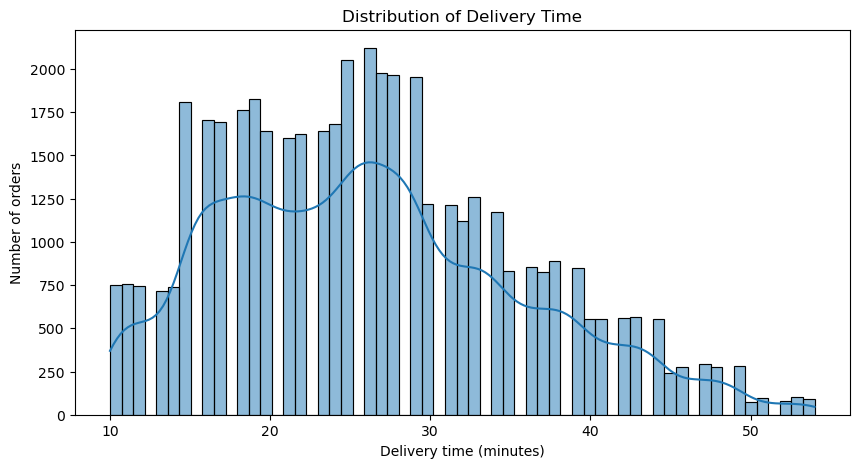

In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df[target], kde=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.show()

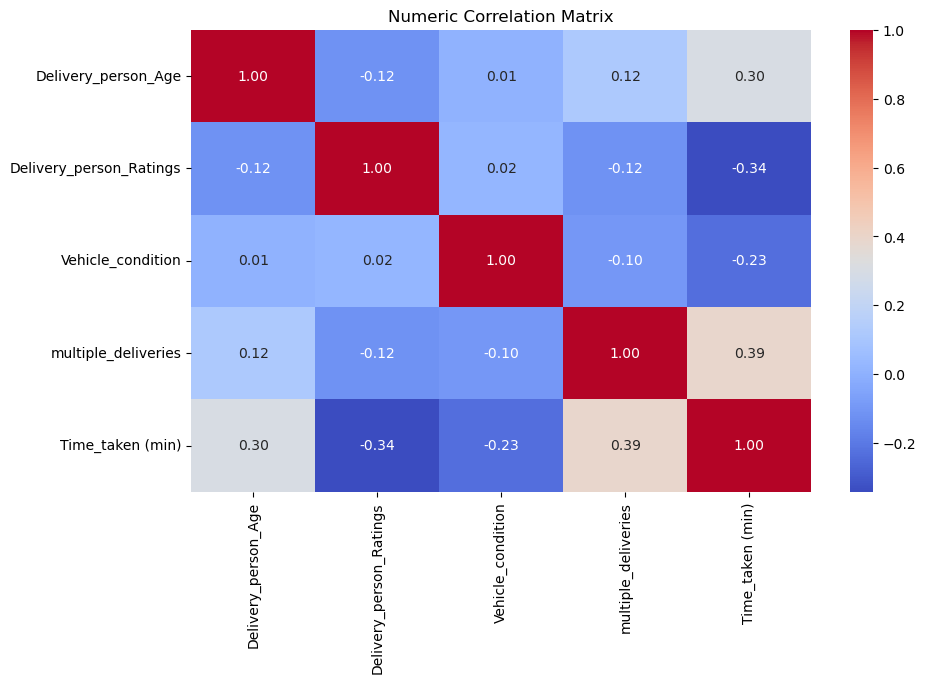

In [3]:
numeric_cols = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "Time_taken (min)"
]

plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numeric Correlation Matrix")
plt.show()

,count,mean,median
Weather_conditions,,,
Cloudy,7533,28.917164,28.0
Fog,7653,28.914674,28.0
Windy,7422,26.118836,26.0
Sandstorms,7494,25.875500,26.0
Stormy,7584,25.868803,26.0
Sunny,7282,21.856770,20.0


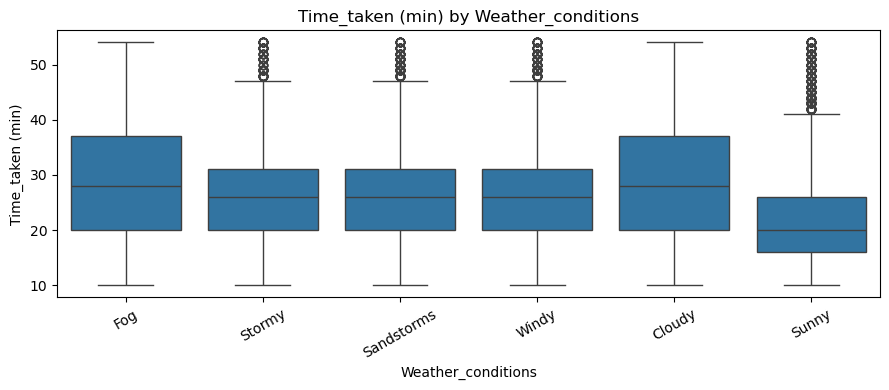

,count,mean,median
Road_traffic_density,,,
Jam,14139,31.176038,31.0
High,4423,27.240109,27.0
Medium,10945,26.699680,27.0
Low,15476,21.266671,20.0


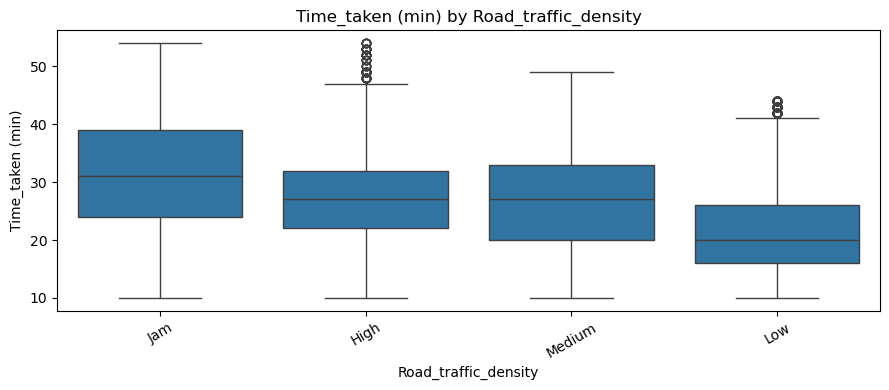

,count,mean,median
Type_of_order,,,
Meal,11456,26.417598,26.0
Snack,11530,26.285603,26.0
Buffet,11277,26.283320,26.0
Drinks,11321,26.187969,25.0


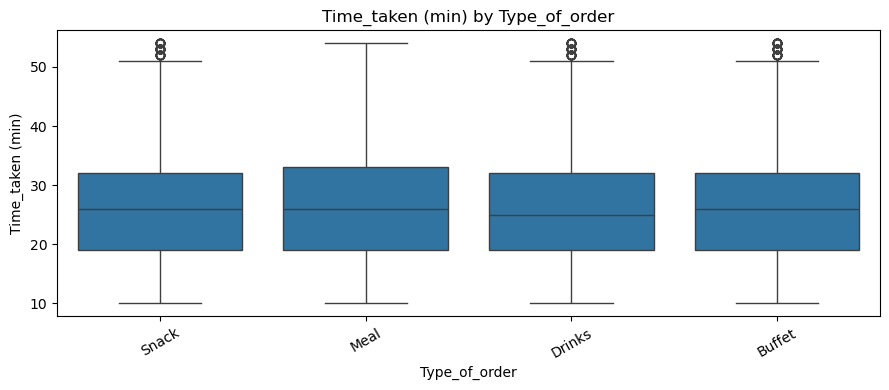

,count,mean,median
Type_of_vehicle,,,
motorcycle,26429,27.605774,26.0
bicycle,68,26.426471,26.0
scooter,15273,24.478819,24.0
electric_scooter,3814,24.470110,24.0


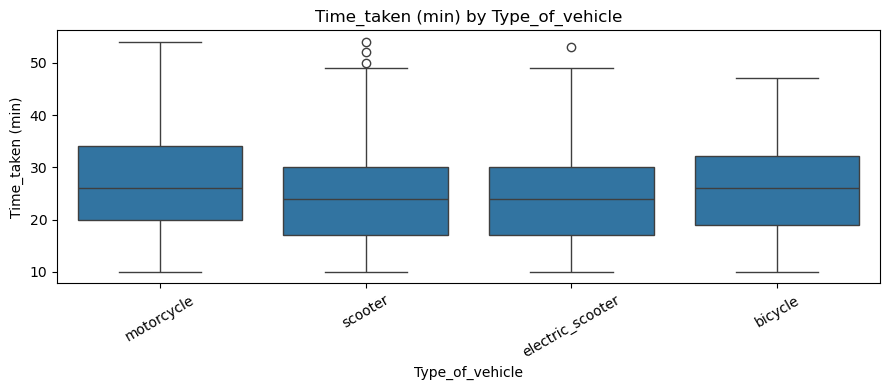

,count,mean,median
Festival,,,
Yes,896,45.517857,45.0
No,44460,25.984121,25.0


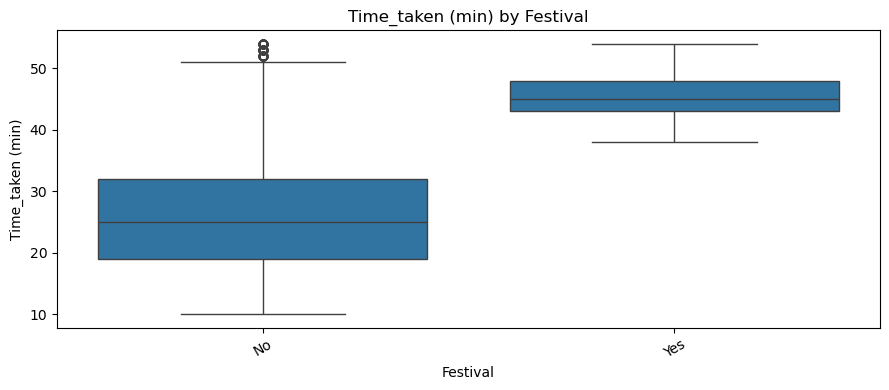

,count,mean,median
City,,,
Semi-Urban,164,49.731707,49.0
Metropolitian,34087,27.314460,26.0
Urban,10133,22.983322,22.0


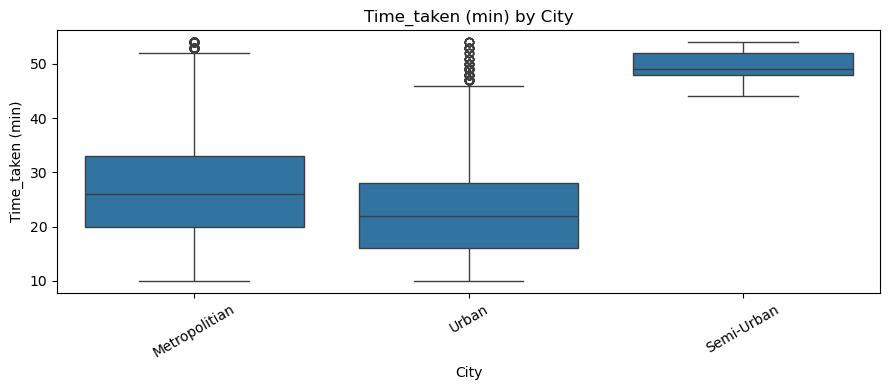

In [4]:
categorical_cols = [
    "Weather_conditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

for col in categorical_cols:
    summary = (
        df.groupby(col)[target]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )
    display(summary)

    plt.figure(figsize=(9, 4))
    sns.boxplot(data=df, x=col, y=target)
    plt.xticks(rotation=30)
    plt.title(f"{target} by {col}")
    plt.tight_layout()
    plt.show()

,count,mean,median
order_hour,,,
8,1817,19.580627,19.0
9,1947,19.543914,19.0
10,2184,19.457875,19.0
11,1768,27.165158,27.0
12,892,26.826233,27.0
13,857,27.529755,27.0
14,717,27.543933,27.0
15,873,23.194731,23.0
16,775,22.932903,24.0


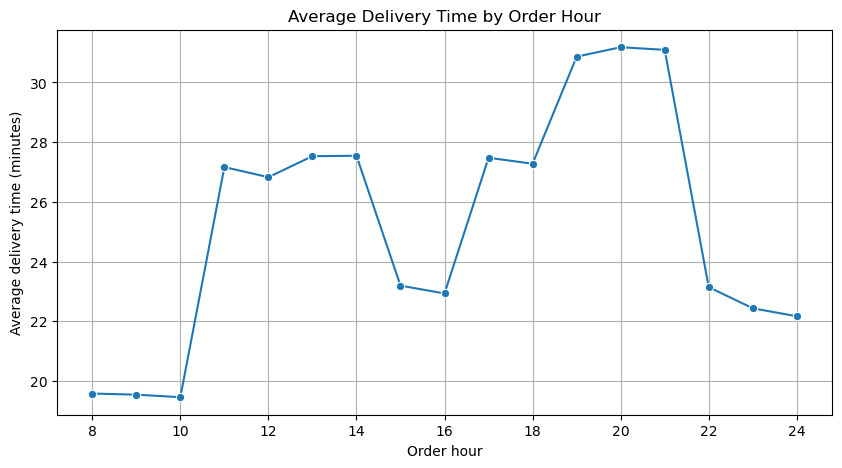

In [5]:
# Order time is available at prediction time, so we can use its hour.
# This is only EDA here; feature engineering comes later.
def parse_time_to_minutes(series):
    text = series.astype("string").str.strip()
    result = pd.Series(np.nan, index=series.index, dtype="float64")

    colon_mask = text.str.contains(":", na=False)
    parsed = pd.to_datetime(text.where(colon_mask), format="%H:%M", errors="coerce")
    result.loc[parsed.notna()] = (
        parsed.loc[parsed.notna()].dt.hour * 60
        + parsed.loc[parsed.notna()].dt.minute
    )

    numeric_fraction = pd.to_numeric(text.where(~colon_mask), errors="coerce")
    fraction_mask = numeric_fraction.between(0, 1, inclusive="both")
    result.loc[fraction_mask] = numeric_fraction.loc[fraction_mask] * 24 * 60

    return result

df["order_minutes"] = parse_time_to_minutes(df["Time_Orderd"])
df["order_hour"] = (df["order_minutes"] // 60).astype("Int64")

hour_summary = df.groupby("order_hour")[target].agg(["count", "mean", "median"])
display(hour_summary)

plt.figure(figsize=(10, 5))
sns.lineplot(data=hour_summary.reset_index(), x="order_hour", y="mean", marker="o")
plt.title("Average Delivery Time by Order Hour")
plt.xlabel("Order hour")
plt.ylabel("Average delivery time (minutes)")
plt.grid(True)
plt.show()

## What to look for

Do not automatically conclude that correlation means causation.

For example, if traffic has a strong relationship with delivery time, that tells us traffic is useful for prediction. It does not prove traffic alone causes every delay.

Also look for **nonlinear patterns**. If delivery time rises sharply for Jam traffic but only slightly between Low and Medium, ordinary Linear Regression may struggle unless the categorical encoding represents those effects appropriately.